In [78]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import seaborn.objects as so

In [90]:
VV2024_semanal = pd.read_csv('volumen_vehicular_2024_detalle_semanal.csv')

In [91]:
circuito = {
    'ENTRE RIOS AV. 678':     'norte',
    'BELGRANO AV. 324':       'este',
    'PASEO COLON AV. 753':    'sur',
    'INDEPENDENCIA AV. 1784': 'oeste',
}
dias = ['VIE', 'LUN', 'MAR', 'MIE', 'JUE']

VV_8am = VV2024_semanal[
    (VV2024_semanal['ubicacion_conteo'].map(circuito) == VV2024_semanal['sentido_circulacion_conteo']) &
    (VV2024_semanal['franja_horaria_conteo'] == 8) &
    VV2024_semanal['dia_semana_conteo'].isin(dias)
].copy()

In [92]:
por_dia = (VV_8am.groupby(['ubicacion_conteo', 'fecha_conteo','sentido_circulacion_conteo','cuarto_hora_conteo'])['conteo_vehiculos'].sum())

In [93]:
prom_8am = (por_dia.groupby(['ubicacion_conteo','sentido_circulacion_conteo', 'cuarto_hora_conteo']).mean().reset_index(name='vehiculos_promedio'))

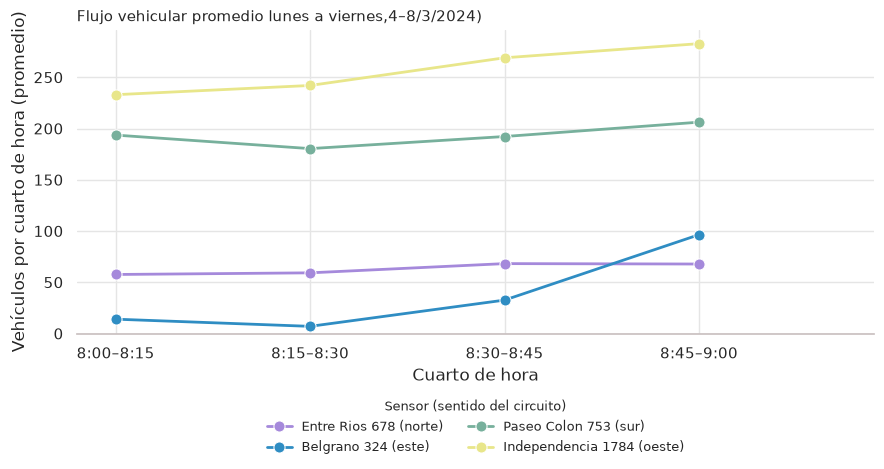

In [100]:
# etiquetas legibles
cuartos = {1: '8:00–8:15', 2: '8:15–8:30', 3: '8:30–8:45', 4: '8:45–9:00'}
prom_8am['cuarto'] = prom_8am['cuarto_hora_conteo'].map(cuartos)
prom_8am['sensor'] = (prom_8am['ubicacion_conteo'].str.replace(' AV.', '', regex=False).str.title()+ ' (' + prom_8am['sentido_circulacion_conteo'] + ')')

orden = ['Entre Rios 678 (norte)', 'Belgrano 324 (este)', 'Paseo Colon 753 (sur)', 'Independencia 1784 (oeste)']
colores = dict(zip(orden, ["#a589db", "#2f8dc3", "#77b09c", "#e8e68a"]))

sns.set_theme(style='whitegrid', rc={'grid.color': '#e5e5e5', 'axes.edgecolor': "#cac1c1"})
fig, ax = plt.subplots(figsize=(9, 5))
sns.lineplot(data=prom_8am, x='cuarto', y='vehiculos_promedio', hue='sensor', hue_order=orden, palette=colores, marker='o', markersize=8, linewidth=2, sort=False, ax=ax)

for s in orden:
    y = prom_8am.loc[(prom_8am['cuarto_hora_conteo'] ==4), 'vehiculos_promedio'].iloc[0]

ax.set_title('Flujo vehicular promedio lunes a viernes,4–8/3/2024)', loc='left', fontsize=11)
ax.set_xlabel('Cuarto de hora')
ax.set_ylabel('Vehículos por cuarto de hora (promedio)')
ax.set_ylim(0, None)
ax.set_xlim(-0.2, 3.9)
ax.legend(title='Sensor (sentido del circuito)', frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2, fontsize=9, title_fontsize=9)
sns.despine(left=True)
plt.tight_layout()
plt.show()